In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

df = pd.read_csv('international-airline-passengers.csv')
df = df.dropna()
df.columns = ['Month', 'Passengers']
df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
df = df.set_index('Month').asfreq('MS')

print('Размер датасета:', df.shape)
display(df.head())

Размер датасета: (144, 1)


,Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0


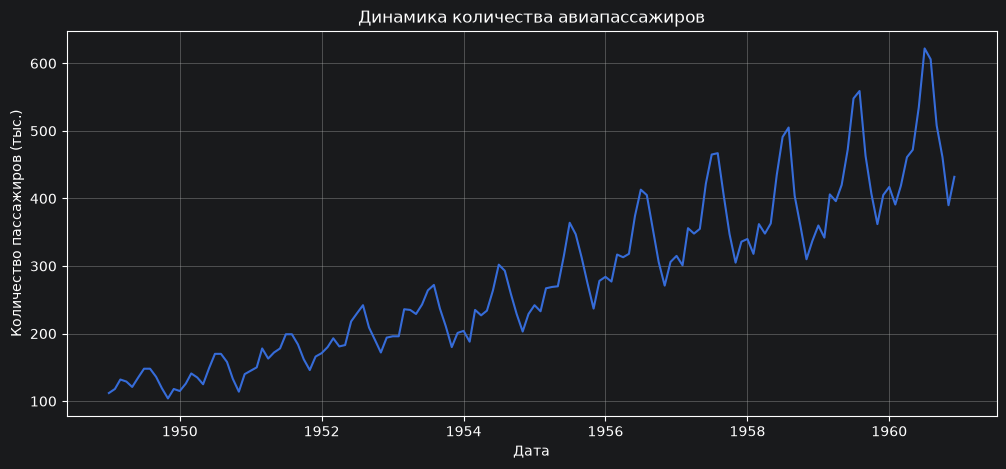

,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [2]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Passengers'])
plt.title('Динамика количества авиапассажиров')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.grid(True)
plt.show()

display(df.describe())

Обучающая выборка: 115
Тестовая выборка: 29


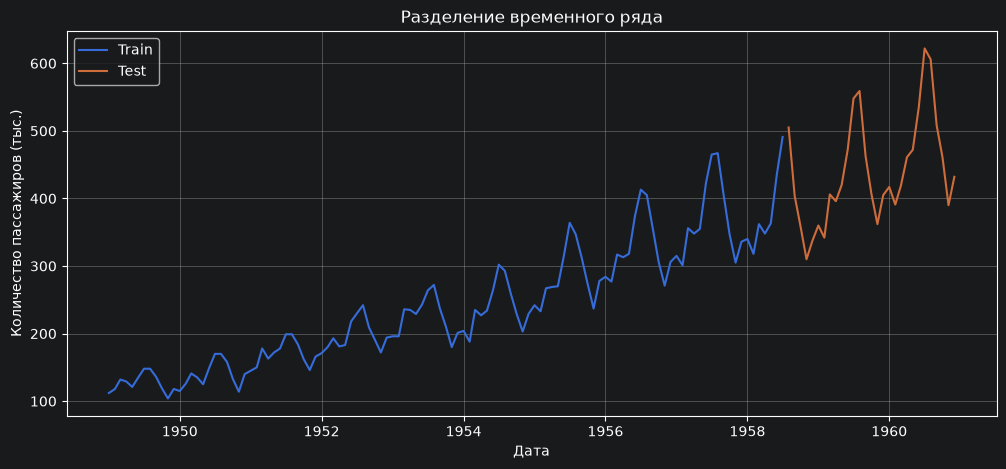

In [3]:
train_size = int(len(df) * 0.8)

train = df.iloc[:train_size]
test = df.iloc[train_size:]

print('Обучающая выборка:', len(train))
print('Тестовая выборка:', len(test))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Passengers'], label='Train')
plt.plot(test.index, test['Passengers'], label='Test')
plt.title('Разделение временного ряда')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

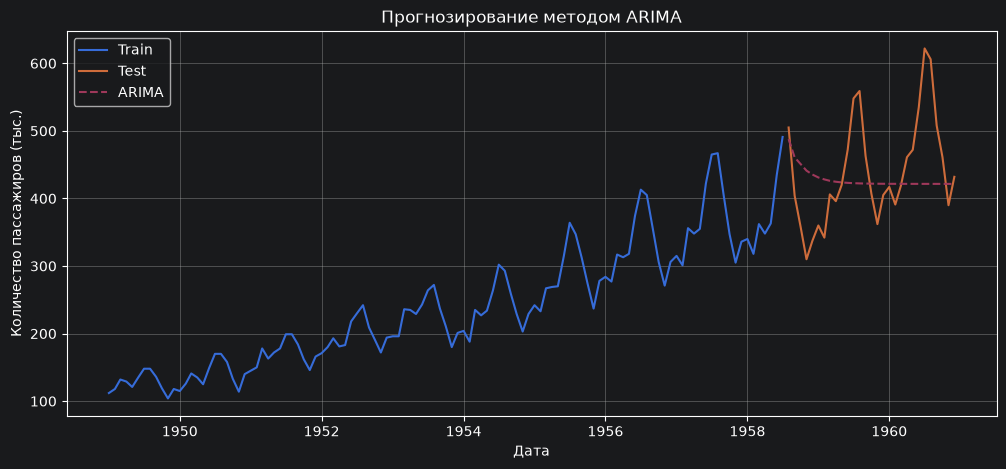

In [4]:
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train['Passengers'], order=(2, 1, 2))
result_arima = model_arima.fit()
forecast_arima = result_arima.forecast(steps=len(test))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Passengers'], label='Train')
plt.plot(test.index, test['Passengers'], label='Test')
plt.plot(test.index, forecast_arima, label='ARIMA', linestyle='--')
plt.title('Прогнозирование методом ARIMA')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
n_lags = 12
values = train['Passengers'].to_numpy()

X_train, y_train = [], []

for i in range(n_lags, len(values)):
    X_train.append(values[i - n_lags:i])
    y_train.append(values[i])

X_train = np.array(X_train)
y_train = np.array(y_train)

print('Размер X_train:', X_train.shape)
print('Размер y_train:', y_train.shape)

Размер X_train: (103, 12)
Размер y_train: (103,)


    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    23.79      1.42558e+48        5          304.576              N/A      3.11s
   1     6.74      1.11491e+12        5          304.576              N/A      2.28s
   2     5.41      8.32821e+07        9          227.645              N/A      2.24s
   3     6.71      1.05687e+08       17          218.128              N/A      2.08s
   4     7.58      1.00285e+08        9          211.673              N/A      1.93s
   5    10.67       9.8746e+07        9          203.591              N/A      1.85s
   6    14.26      2.93191e+07       15          196.818              N/A      1.79s
   7    15.92      1.01491e+08       25           190.62              N/A      1.70s
   8    17.36      6.02464e+07       25          190.555              N/A  

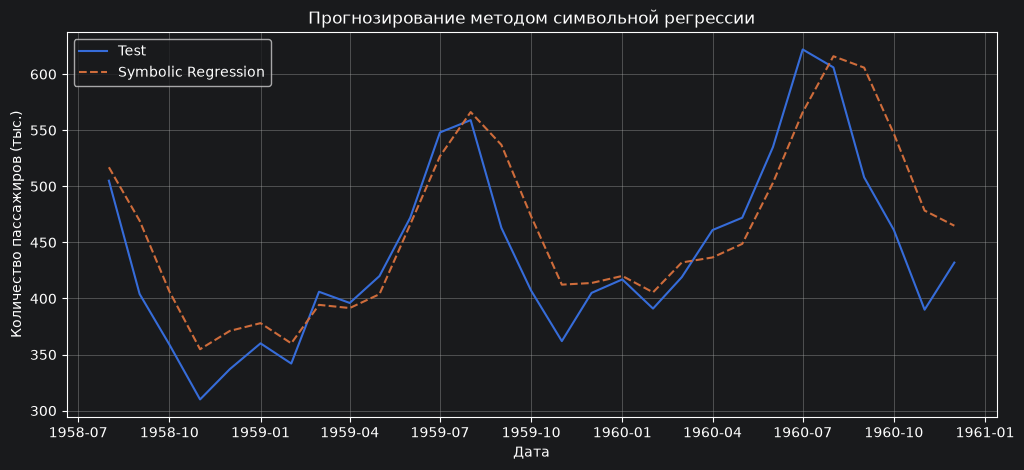

In [7]:
from gplearn.genetic import SymbolicRegressor

model_symbolic = SymbolicRegressor(
    population_size=1000,
    generations=20,
    tournament_size=20,
    stopping_criteria=0.01,
    function_set=('add', 'sub', 'mul', 'div'),
    metric='mse',
    parsimony_coefficient=0.001,
    random_state=42,
    verbose=1
)

model_symbolic.fit(X_train, y_train)
print('Найденная формула:')
print(model_symbolic._program)

# Рекурсивное прогнозирование
history = list(values[-n_lags:])
forecast_symbolic = []

for _ in range(len(test)):
    X_next = np.array(history[-n_lags:]).reshape(1, -1)
    prediction = model_symbolic.predict(X_next)[0]
    forecast_symbolic.append(prediction)
    history.append(prediction)

forecast_symbolic = np.array(forecast_symbolic)

# Визуализация прогноза
plt.figure(figsize=(12, 5))
plt.plot(test.index, test['Passengers'], label='Test')
plt.plot(test.index, forecast_symbolic,
         label='Symbolic Regression', linestyle='--')
plt.title('Прогнозирование методом символьной регрессии')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

Найденная формула:
y = 0.9093*x1 - 0.0474*x6 + 0.0999*x8 - 0.078*x9 + 0.2331*x12 + 0.0382


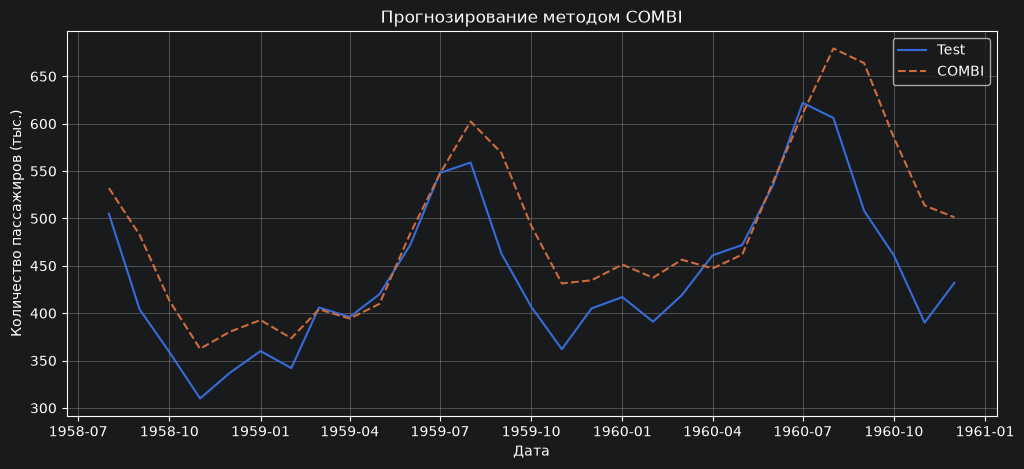

In [8]:
import gmdh

# Обучение модели
model_combi = gmdh.Combi()
model_combi.fit(X_train, y_train, test_size=0.2)

print('Найденная формула:')
print(model_combi.get_best_polynomial())

# Рекурсивное прогнозирование
history = list(values[-n_lags:])
forecast_combi = []

for _ in range(len(test)):
    X_next = np.array(history[-n_lags:]).reshape(1, -1)
    prediction = model_combi.predict(X_next)[0]
    forecast_combi.append(prediction)
    history.append(prediction)

forecast_combi = np.array(forecast_combi)

# Визуализация прогноза
plt.figure(figsize=(12, 5))
plt.plot(test.index, test['Passengers'], label='Test')
plt.plot(test.index, forecast_combi, label='COMBI', linestyle='--')
plt.title('Прогнозирование методом COMBI')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

Найденная формула:
y = 0.8717*x1 + 0.1606*x12 + 0.0002*x1*x12 + 8.6606


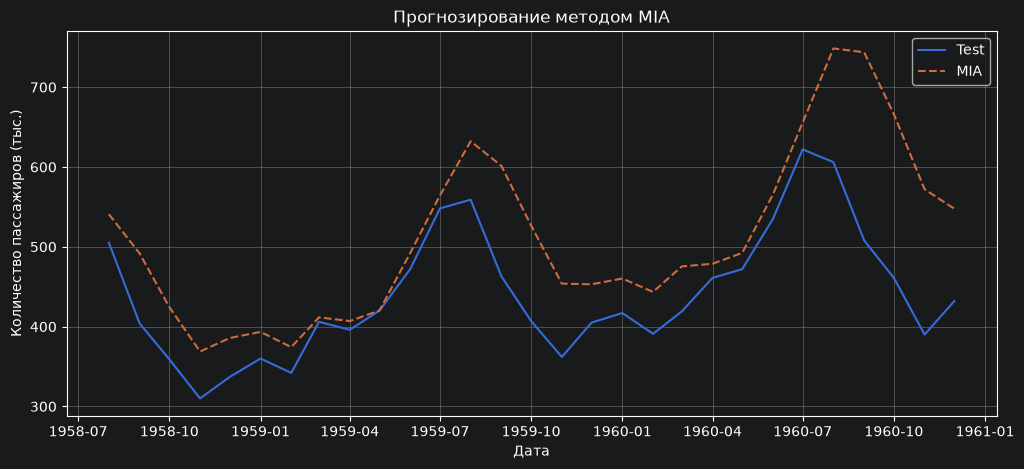

In [10]:
# Обучение модели
model_mia = gmdh.Mia()

model_mia.fit(
    X_train,
    y_train,
    test_size=0.2,
    polynomial_type=gmdh.PolynomialType.LINEAR_COV
)

print('Найденная формула:')
print(model_mia.get_best_polynomial())

# Рекурсивное прогнозирование
history = list(values[-n_lags:])
forecast_mia = []

for _ in range(len(test)):
    X_next = np.array(history[-n_lags:]).reshape(1, -1)
    prediction = model_mia.predict(X_next)[0]
    forecast_mia.append(prediction)
    history.append(prediction)

forecast_mia = np.array(forecast_mia)

# Визуализация прогноза
plt.figure(figsize=(12, 5))
plt.plot(test.index, test['Passengers'], label='Test')
plt.plot(test.index, forecast_mia, label='MIA', linestyle='--')
plt.title('Прогнозирование методом MIA')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

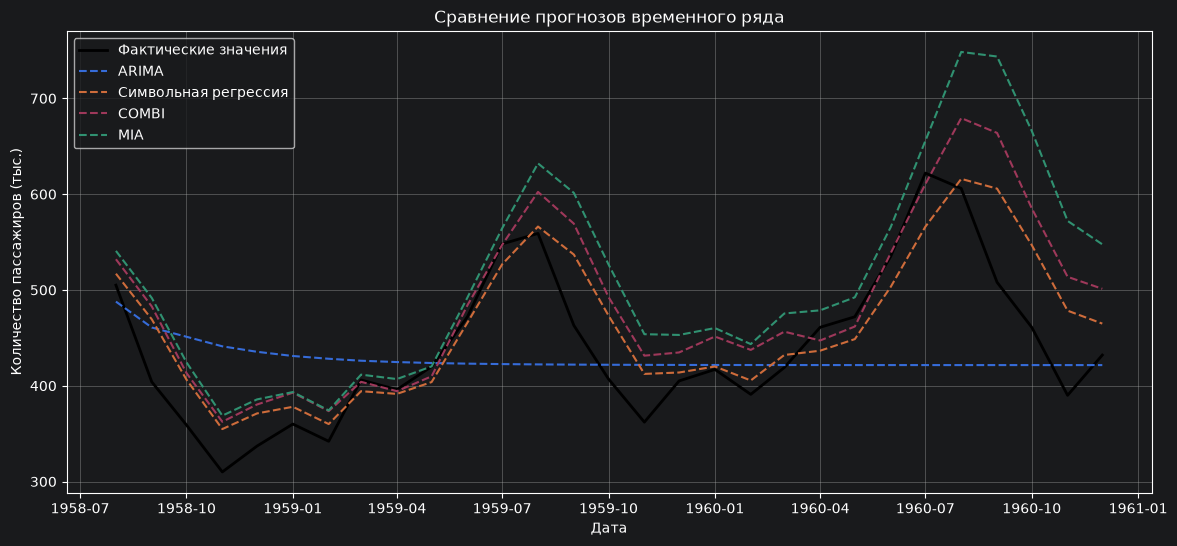

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test['Passengers'],
         label='Фактические значения', color='black', linewidth=2)

plt.plot(test.index, forecast_arima,
         label='ARIMA', linestyle='--')

plt.plot(test.index, forecast_symbolic,
         label='Символьная регрессия', linestyle='--')

plt.plot(test.index, forecast_combi,
         label='COMBI', linestyle='--')

plt.plot(test.index, forecast_mia,
         label='MIA', linestyle='--')

plt.title('Сравнение прогнозов временного ряда')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

forecasts = {
    'ARIMA': forecast_arima,
    'Символьная регрессия': forecast_symbolic,
    'COMBI': forecast_combi,
    'MIA': forecast_mia
}

results = []

for name, forecast in forecasts.items():
    results.append({
        'Модель': name,
        'MAE': mean_absolute_error(test['Passengers'], forecast),
        'RMSE': np.sqrt(mean_squared_error(test['Passengers'], forecast)),
        'MAPE (%)': mean_absolute_percentage_error(
            test['Passengers'], forecast) * 100
    })

results = pd.DataFrame(results).sort_values('RMSE')

display(results.round(2))

,Модель,MAE,RMSE,MAPE (%)
1,Символьная регрессия,34.03,43.74,7.99
2,COMBI,47.75,62.54,11.26
0,ARIMA,63.55,82.51,14.22
3,MIA,69.70,92.21,16.02
